# Project 3 - Portfolio, Execution, Robustness and Risk

This notebook combines the retained strategies into portfolios and then tries hard to break the
result.

Everything here uses the **walk-forward out-of-sample** strategy returns from notebook 2. There is
no second in-sample track.

**Three strategies, not four.** Pairs trading was rejected in notebook 2: its apparent edge does not
survive switching the spread from price levels to log prices, nor weighting the legs by the hedge
ratio that defines the spread. A result that moves that much under innocuous implementation choices
cannot be allocated capital, so it appears in no portfolio and in none of the analysis below.

Blocks:
1. rebuild the three retained out-of-sample strategy return streams,
2. Method A: inverse-volatility weights,
3. Method B: Markowitz mean-variance weights,
4. execution realism (turnover cap, portfolio-level costs, volatility target) and the portfolio grid,
5. correlations: what does AAA actually add?
6. robustness: sub-periods, cost sensitivity, parameter sensitivity, overlay sensitivity,
7. risk: stress episodes, Monte Carlo, drawdown episodes, regime-conditioned performance.

In [1]:
from pathlib import Path  # Work with repository paths safely.
import sys  # Let us modify the import path for notebook execution.

project_root = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()  # Find the repository root.

if str(project_root) not in sys.path:  # Only append the path once.
    sys.path.append(str(project_root))  # Make src/ importable from the notebook.

# Load IPython autoreload so edits in src/ are picked up after rerunning cells.
%load_ext autoreload
%autoreload 2

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.analysis.robustness import (calendar_year_returns, cost_sensitivity, parameter_grid,
                                     regime_conditioned_table, rolling_correlation, sharpe, subperiod_sharpes)
from src.backtest.engine import (drawdown_curve, equity_curve, performance_metrics,
                                 positions_to_strategy_returns, rolling_sharpe_ratio)
from src.models.regime import build_regime_features, fit_hmm_regime_model, infer_regimes
from src.portfolio.construction import (MARKOWITZ_VARIANTS, METHOD_LABELS, apply_volatility_target,
                                        build_portfolio, combine_strategy_returns, inverse_volatility_weights,
                                        markowitz_avg_weights_table, markowitz_metrics_table,
                                        run_markowitz_variants, run_markowitz_variants_pre_cost,
                                        run_portfolio_grid, strategy_correlation)
from src.risk.drawdowns import drawdown_table
from src.risk.monte_carlo import monte_carlo_paths_frame, monte_carlo_table
from src.risk.stress import stress_test
from src.strategies import adaptive_allocation
from src.strategies.benchmarks import buy_and_hold_positions, sixty_forty_positions
from src.strategies.regime_switching import map_regimes_to_labels
from src.utils.config import (AAA_CONFIG, COST_CONFIG, DATA_CONFIG, PORTFOLIO_CONFIG,
                              RETAINED_STRATEGIES, ROBUSTNESS_CONFIG, STRATEGY_LABELS)
from src.utils.data_loader import build_market_data_bundle

TC, SLIP = COST_CONFIG.transaction_cost_bps, COST_CONFIG.slippage_bps
results_dir = project_root / "results"

## Step 1 - Rebuild the out-of-sample strategy return streams

The walk-forward positions are read from `results/cache/`, written by notebook 2 or by
`python run_research.py`. Reading them keeps this notebook fast and guarantees that every number
here matches the research summaries exactly.

In [3]:
market_data = build_market_data_bundle()
prices, returns = market_data.prices, market_data.simple_returns
log_returns, realized_vol = market_data.log_returns, market_data.realized_volatility
benchmark_asset = DATA_CONFIG.benchmark_symbol

# Only the retained strategies; pairs trading was rejected in notebook 2.
positions = {n: pd.read_csv(results_dir / "cache" / f"wf_positions_{n}.csv", index_col=0, parse_dates=True)
             for n in RETAINED_STRATEGIES}
backtests = {n: positions_to_strategy_returns(p, returns, TC, SLIP) for n, p in positions.items()}
strategies = pd.DataFrame({n: bt["net_return"] for n, bt in backtests.items()})

spy = positions_to_strategy_returns(buy_and_hold_positions(returns.index, benchmark_asset), returns, TC, SLIP)["net_return"].rename("SPY")
sixty_forty = positions_to_strategy_returns(sixty_forty_positions(returns.index, benchmark_asset, "TLT"), returns, TC, SLIP)["net_return"].rename("60/40")

oos_start = strategies.dropna(how="all").index.min()
print("out-of-sample window:", oos_start.date(), "to", strategies.index.max().date())
strategies.rename(columns=STRATEGY_LABELS).describe().round(4)

out-of-sample window: 2006-07-05 to 2026-08-17


,VolTiming,RegimeHMM,AAA
count,5061.0000,5061.0000,5061.0000
mean,0.0004,0.0003,0.0003
std,0.0086,0.0054,0.0067
min,-0.0543,-0.0581,-0.0515
25%,-0.0038,-0.0015,-0.0028
50%,0.0007,0.0000,0.0005
75%,0.0055,0.0027,0.0038
max,0.0430,0.0320,0.0448


## Step 2 - Method A: inverse-volatility portfolio

Each strategy return stream is treated like an asset; strategies that have been less volatile
recently get more weight. This uses risk estimates only, never expected returns.

We start with the original two-strategy book (volatility timing and regime switching). Pairs trading
is excluded because it fails after costs; block 4 shows what including it would do.

In [4]:
orig2 = strategies[list(PORTFOLIO_CONFIG.menus["Orig2"])].dropna(how="any")
weights_orig2 = inverse_volatility_weights(orig2)
raw_orig2 = combine_strategy_returns(orig2, weights_orig2)
vol_targeted_orig2 = apply_volatility_target(raw_orig2, COST_CONFIG.target_portfolio_vol)

display((weights_orig2.rename(columns=STRATEGY_LABELS).mean() * 100).round(1).to_frame("avg weight %"))
pd.Series(performance_metrics(vol_targeted_orig2), name="Orig2 inverse-vol, vol-targeted").to_frame()

,avg weight %
VolTiming,37.3
RegimeHMM,62.7


,"Orig2 inverse-vol, vol-targeted"
sharpe_ratio,0.789656
sortino_ratio,0.966195
cagr,0.080065
max_drawdown,-0.231706
calmar_ratio,0.345545
volatility,0.104485
var_95,0.010367
expected_shortfall_95,0.016743


### Now add AAA

The whole point of the update is this comparison: the same weighting method, the same costs, the
same window, with adaptive asset allocation added as a third building block.

In [5]:
core3 = strategies[list(PORTFOLIO_CONFIG.menus["Core3"])].dropna(how="any")
weights_core3 = inverse_volatility_weights(core3)
vol_targeted_core3 = apply_volatility_target(
    combine_strategy_returns(core3, weights_core3), COST_CONFIG.target_portfolio_vol)

display((weights_core3.rename(columns=STRATEGY_LABELS).mean() * 100).round(1).to_frame("avg weight %"))
pd.DataFrame({
    "Orig2 (no AAA)": performance_metrics(vol_targeted_orig2),
    "Core3 (with AAA)": performance_metrics(vol_targeted_core3),
}).round(3)

,avg weight %
VolTiming,23.7
RegimeHMM,41.1
AAA,35.2


,Orig2 (no AAA),Core3 (with AAA)
sharpe_ratio,0.790,0.928
sortino_ratio,0.966,1.166
cagr,0.080,0.096
max_drawdown,-0.232,-0.162
calmar_ratio,0.346,0.592
volatility,0.104,0.105
var_95,0.010,0.010
expected_shortfall_95,0.017,0.016


## Step 3 - Method B: Markowitz mean-variance portfolio

Rolling long-only max-Sharpe weights in five specifications: baseline, Ledoit-Wolf shrinkage, a 70%
weight cap, shrinkage plus cap, and a concentration penalty (max Sharpe minus lambda times the sum of
squared weights). Markowitz uses expected returns *and* covariances, which makes it more expressive
but far more fragile, because expected returns are estimated with enormous noise.

In [6]:
markowitz_pre_cost = run_markowitz_variants_pre_cost(core3)
markowitz_metrics_table(markowitz_pre_cost).round(3)

,markowitz_baseline,markowitz_shrinkage,markowitz_cap70,markowitz_shrinkage_cap70,markowitz_concentration
sharpe_ratio,1.351,1.364,1.252,1.270,1.348
sortino_ratio,1.756,1.786,1.630,1.661,1.770
cagr,0.147,0.149,0.135,0.137,0.146
max_drawdown,-0.170,-0.169,-0.169,-0.170,-0.161
calmar_ratio,0.867,0.877,0.794,0.804,0.909
volatility,0.106,0.106,0.105,0.105,0.106
var_95,0.010,0.010,0.011,0.010,0.010
expected_shortfall_95,0.016,0.016,0.016,0.016,0.016


In [7]:
markowitz_avg_weights_table(markowitz_pre_cost).rename(index=STRATEGY_LABELS)

,markowitz_baseline,markowitz_shrinkage,markowitz_cap70,markowitz_shrinkage_cap70,markowitz_concentration
VolTiming,31.2,33.8,31.6,32.9,31.3
RegimeHMM,30.5,27.9,35.1,33.9,30.3
AAA,38.3,38.2,33.3,33.1,38.4


## Step 4 - Execution realism and the portfolio grid

An optimizer may want to trade too much. Every portfolio below goes through the same pipeline:

$$\text{weights} \;\to\; \text{turnover cap (0.35)} \;\to\; \text{portfolio-level costs (7 bps)}
\;\to\; \text{10\% volatility target}$$

We then run the full **grid**: four strategy menus against four weighting methods. Comparing menus
that differ by one strategy is how the contribution of that strategy is measured.

In [8]:
for name, members in PORTFOLIO_CONFIG.menus.items():
    print(f"{name:6s}", [STRATEGY_LABELS[m] for m in members])

grid, portfolios, results = run_portfolio_grid(strategies, PORTFOLIO_CONFIG.menus, PORTFOLIO_CONFIG.methods)
sharpe_grid = grid.pivot(index="menu", columns="method", values="sharpe_ratio").astype(float)
sharpe_grid = sharpe_grid.reindex(index=list(PORTFOLIO_CONFIG.menus),
                                  columns=list(PORTFOLIO_CONFIG.methods)).rename(columns=METHOD_LABELS)
maxdd_grid = grid.pivot(index="menu", columns="method", values="max_drawdown").astype(float)
maxdd_grid = maxdd_grid.reindex(index=list(PORTFOLIO_CONFIG.menus),
                                columns=list(PORTFOLIO_CONFIG.methods)).rename(columns=METHOD_LABELS)
display(sharpe_grid.round(2))
maxdd_grid.round(3)

Orig2  ['VolTiming', 'RegimeHMM']
Core3  ['VolTiming', 'RegimeHMM', 'AAA']


method,Equal weight,Inverse vol,Markowitz,Markowitz regularized
menu,,,,
Orig2,0.79,0.77,0.72,0.72
Core3,0.96,0.88,0.82,0.82


method,Equal weight,Inverse vol,Markowitz,Markowitz regularized
menu,,,,
Orig2,-0.238,-0.235,-0.180,-0.214
Core3,-0.160,-0.168,-0.211,-0.212


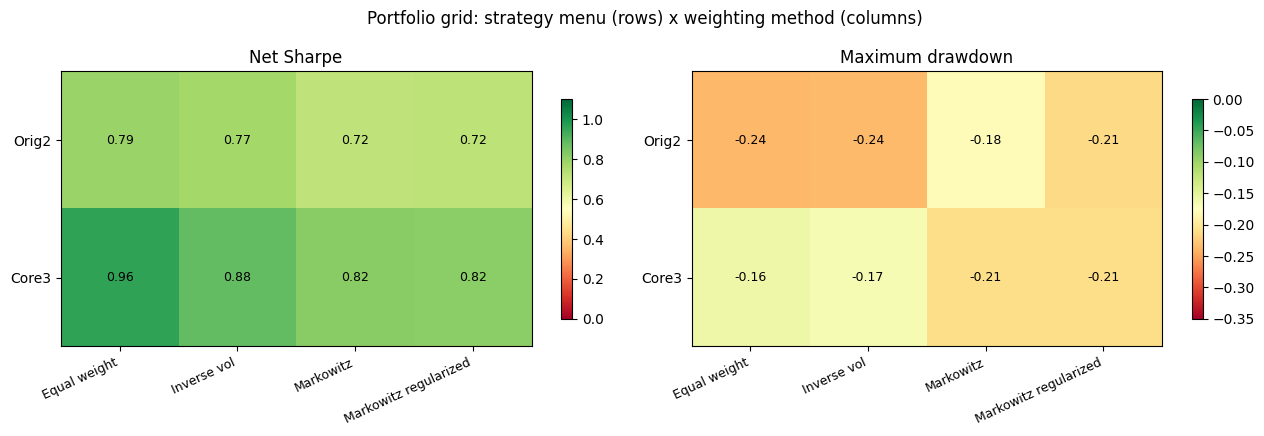

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, (table, title, vmin, vmax) in zip(axes, ((sharpe_grid, "Net Sharpe", 0.0, 1.1),
                                                 (maxdd_grid, "Maximum drawdown", -0.35, 0.0))):
    im = ax.imshow(table.values, cmap="RdYlGn", vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(table.shape[1])); ax.set_xticklabels(table.columns, rotation=25, ha="right", fontsize=9)
    ax.set_yticks(range(table.shape[0])); ax.set_yticklabels(table.index)
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            ax.text(j, i, f"{table.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.suptitle("Portfolio grid: strategy menu (rows) x weighting method (columns)")
plt.tight_layout()
plt.show()

In [10]:
headline = portfolios[f"{PORTFOLIO_CONFIG.headline_menu}_{PORTFOLIO_CONFIG.headline_method}"]
port_start = headline.index.min()
key = {"Orig2 inv-vol": portfolios["Orig2_inverse_volatility"],
       "Orig2 equal": portfolios["Orig2_equal_weight"],
       "Core3 inv-vol": headline,
       "Core3 equal": portfolios["Core3_equal_weight"],
       "Core3 Markowitz reg.": portfolios["Core3_markowitz_concentration"],
       "SPY": spy.loc[port_start:], "60/40": sixty_forty.loc[port_start:]}
key_metrics = pd.DataFrame({n: performance_metrics(r.dropna()) for n, r in key.items()})
key_metrics.loc["start"] = pd.Series({n: r.dropna().index.min().date() for n, r in key.items()})
key_metrics

,Orig2 inv-vol,Orig2 equal,Core3 inv-vol,Core3 equal,Core3 Markowitz reg.,SPY,60/40
sharpe_ratio,0.770219,0.787179,0.881236,0.955615,0.815183,0.643784,0.798148
sortino_ratio,0.938139,0.983592,1.096274,1.219188,1.048629,0.785689,1.036671
cagr,0.077935,0.079966,0.090866,0.100263,0.083992,0.112238,0.087992
max_drawdown,-0.235184,-0.23764,-0.167939,-0.159731,-0.211909,-0.551894,-0.299228
calmar_ratio,0.331379,0.336499,0.541068,0.627701,0.39636,0.203369,0.294063
volatility,0.104572,0.104731,0.10498,0.105887,0.105839,0.194739,0.113783
var_95,0.010336,0.010548,0.010454,0.010657,0.010874,0.018037,0.010716
expected_shortfall_95,0.016792,0.016457,0.016602,0.016346,0.016215,0.029904,0.01688
start,2006-10-02,2006-07-05,2006-10-02,2006-07-05,2007-07-05,2006-10-02,2006-10-02


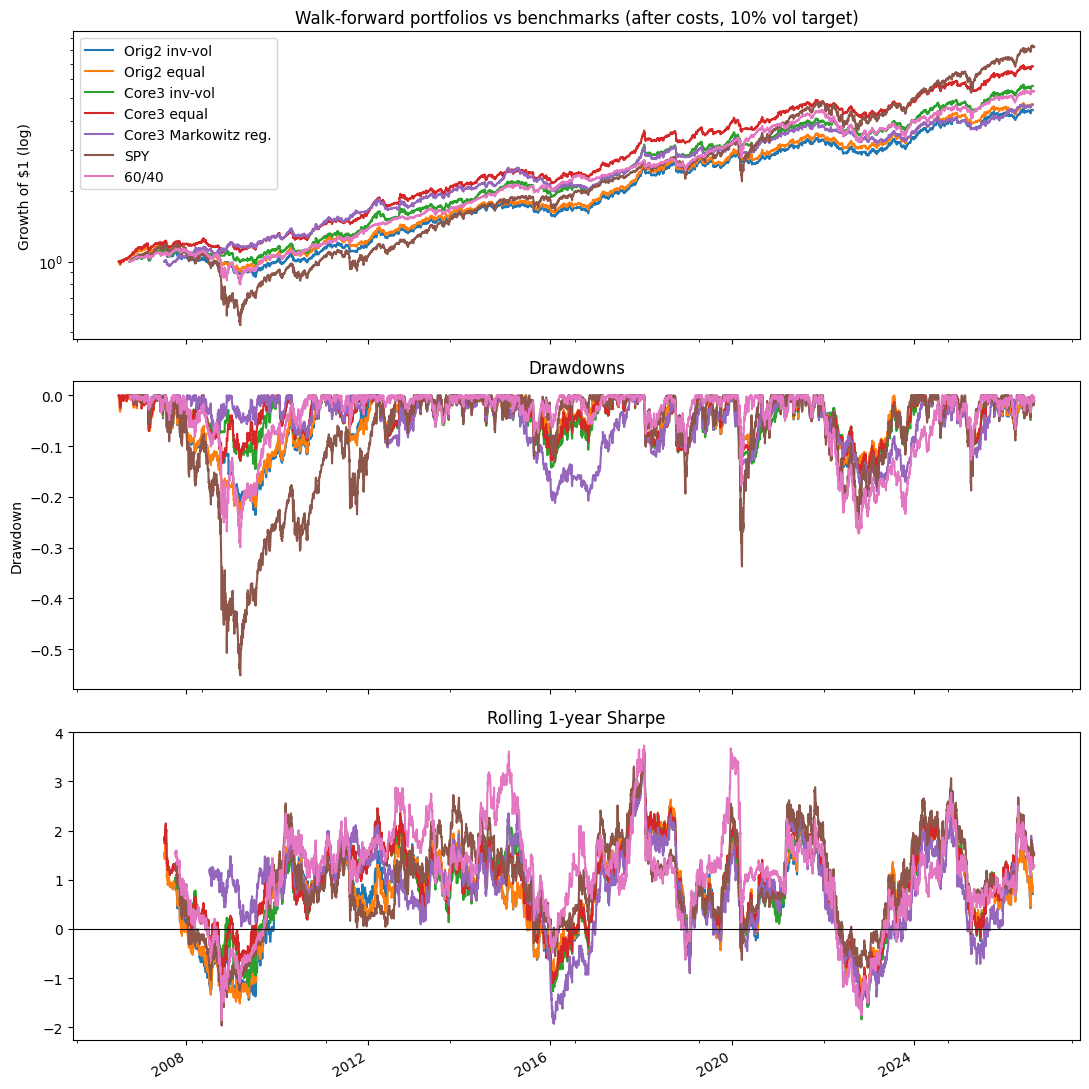

In [11]:
fig, axes = plt.subplots(3, 1, figsize=(11, 11), sharex=True)
curves = pd.DataFrame({n: equity_curve(r.dropna()) for n, r in key.items()})
curves.plot(ax=axes[0], title="Walk-forward portfolios vs benchmarks (after costs, 10% vol target)", logy=True)
axes[0].set_ylabel("Growth of $1 (log)")
curves.apply(drawdown_curve).plot(ax=axes[1], title="Drawdowns", legend=False)
axes[1].set_ylabel("Drawdown")
pd.DataFrame({n: rolling_sharpe_ratio(r.dropna(), 252) for n, r in key.items()}).plot(
    ax=axes[2], title="Rolling 1-year Sharpe", legend=False)
axes[2].axhline(0, color="black", lw=0.8)
plt.tight_layout()
plt.show()

## Step 5 - Correlations: what does AAA actually add?

Diversification only helps when the strategies are not the same bet. Volatility timing and regime
switching are both scaled SPY exposure, so they should be highly correlated with each other. AAA
trades a different menu on a different signal, so it should not be.

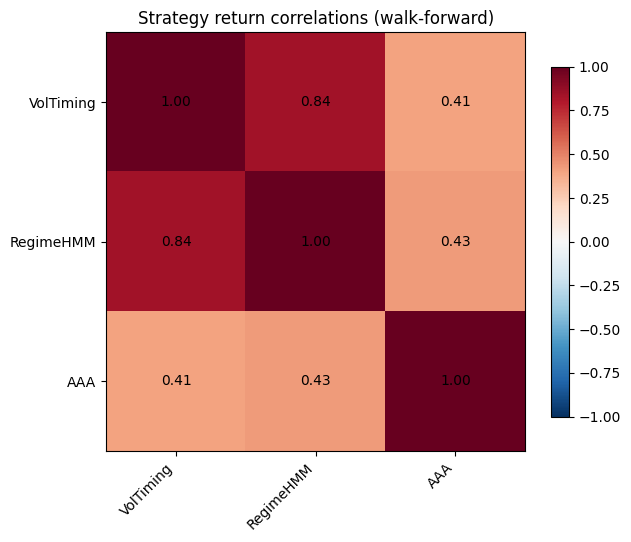

,VolTiming,RegimeHMM,AAA
VolTiming,1.00,0.84,0.41
RegimeHMM,0.84,1.00,0.43
AAA,0.41,0.43,1.00


In [12]:
corr = strategy_correlation(strategies).rename(index=STRATEGY_LABELS, columns=STRATEGY_LABELS)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=10)
fig.colorbar(im, shrink=0.8)
ax.set_title("Strategy return correlations (walk-forward)")
plt.tight_layout()
plt.show()
corr.round(2)

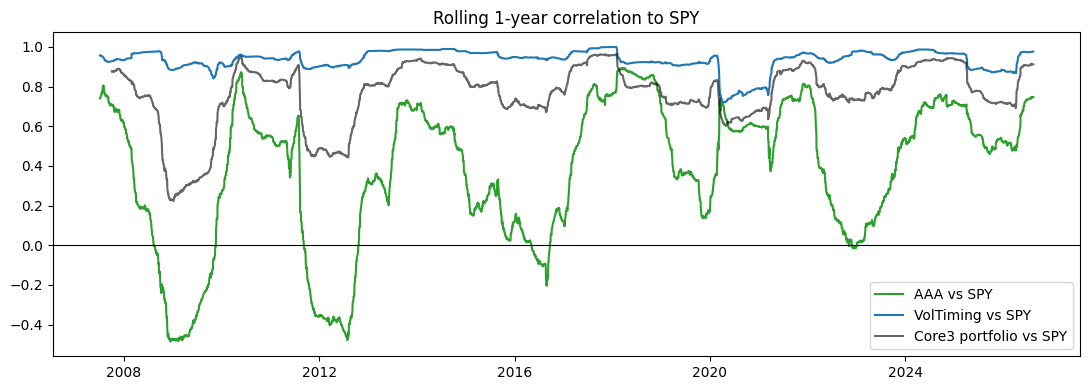

In [13]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(rolling_correlation(strategies["adaptive_allocation"], spy, 252), label="AAA vs SPY", color="tab:green")
ax.plot(rolling_correlation(strategies["volatility_timing"], spy, 252), label="VolTiming vs SPY", color="tab:blue")
ax.plot(rolling_correlation(headline, spy, 252), label="Core3 portfolio vs SPY", color="black", alpha=0.6)
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Rolling 1-year correlation to SPY")
ax.legend()
plt.tight_layout()
plt.show()

## Step 6 - Robustness

Four questions: is the edge concentrated in one period, does it survive higher costs, does it depend
on lucky parameters, and does it depend on the overlay settings?

### 6a. Sub-period stability

In [14]:
named = {STRATEGY_LABELS[n]: strategies[n] for n in RETAINED_STRATEGIES}
sub_strategies = subperiod_sharpes({**named, "SPY": spy.loc[oos_start:], "60/40": sixty_forty.loc[oos_start:]})
sub_ports = subperiod_sharpes(key)
display(sub_strategies.round(2))
sub_ports.round(2)

,2006-09,2010-13,2014-17,2018-21,2022-26
VolTiming,0.29,1.06,0.85,0.97,0.78
RegimeHMM,0.20,1.28,0.83,0.67,0.66
AAA,1.41,0.51,0.75,0.62,0.95
SPY,0.07,0.96,0.99,0.88,0.76
60/40,0.27,1.56,1.52,1.19,0.38


,2006-09,2010-13,2014-17,2018-21,2022-26
Orig2 inv-vol,0.03,1.25,0.89,0.88,0.66
Orig2 equal,0.20,1.18,0.90,0.91,0.68
Core3 inv-vol,0.41,1.23,1.03,0.88,0.77
Core3 equal,0.72,1.30,0.98,0.98,0.79
Core3 Markowitz reg.,0.98,1.22,0.72,0.78,0.48
SPY,0.02,0.96,0.99,0.88,0.76
60/40,0.17,1.56,1.52,1.19,0.38


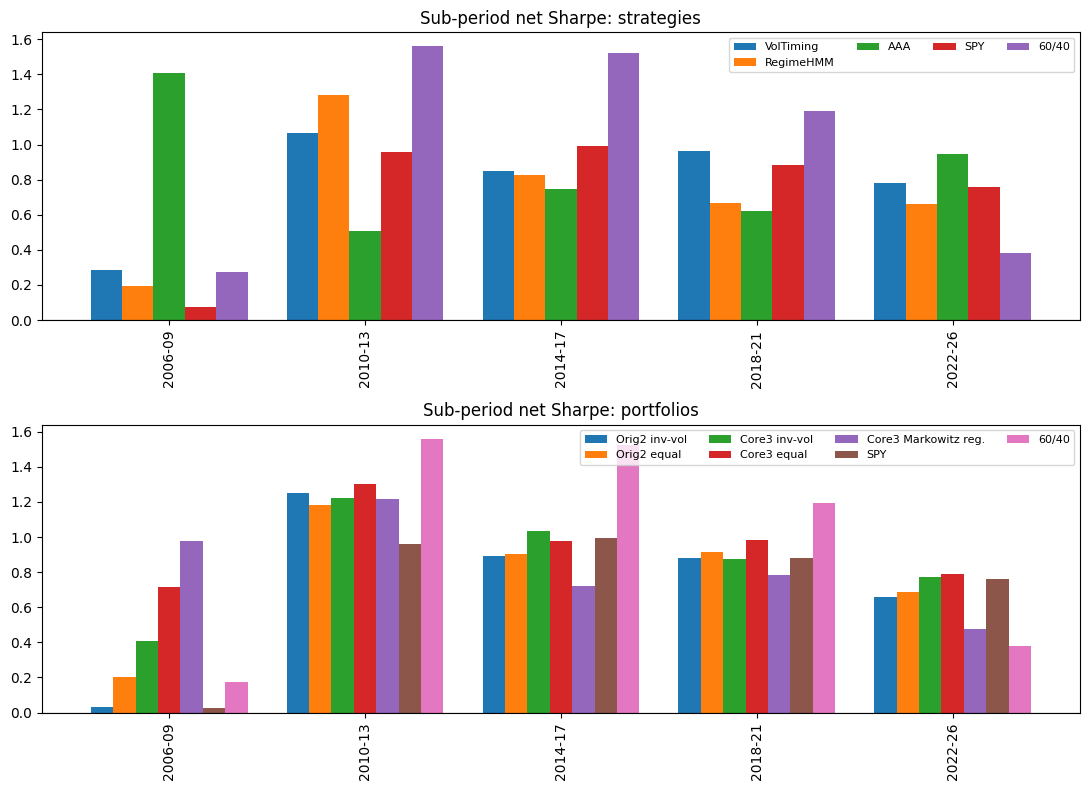

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(11, 8))
sub_strategies.T.plot.bar(ax=axes[0], width=0.8, title="Sub-period net Sharpe: strategies")
sub_ports.T.plot.bar(ax=axes[1], width=0.8, title="Sub-period net Sharpe: portfolios")
for ax in axes:
    ax.axhline(0, color="black", lw=0.8)
    ax.legend(ncol=4, fontsize=8)
plt.tight_layout()
plt.show()

### 6b. Cost sensitivity

The deployed assumption is 7 bps per unit of turnover (5 commission and spread, 2 slippage). We
recompute net Sharpe from 0 to 30 bps. For the portfolios the same rate is charged at both the
strategy level and the portfolio-rebalancing level, which is the conservative choice.

In [16]:
cost_strategies = cost_sensitivity({STRATEGY_LABELS[n]: p for n, p in positions.items()}, returns)
rows = {}
for bps in ROBUSTNESS_CONFIG.cost_grid_bps:
    rets = pd.DataFrame({n: positions_to_strategy_returns(p, returns, bps, 0.0)["net_return"]
                         for n, p in positions.items()})
    rows[f"{bps:g}bps"] = {m: sharpe(build_portfolio(rets[list(PORTFOLIO_CONFIG.menus[m])].dropna(),
                                                     "inverse_volatility", transaction_cost_bps=bps,
                                                     slippage_bps=0.0)["returns"])
                           for m in PORTFOLIO_CONFIG.menus}
cost_ports = pd.DataFrame(rows).T
display(cost_strategies.round(2))
cost_ports.round(2)

,0bps,5bps,7bps,10bps,15bps,20bps,30bps
VolTiming,0.85,0.82,0.81,0.79,0.77,0.74,0.69
RegimeHMM,0.84,0.77,0.75,0.71,0.64,0.57,0.43
AAA,0.88,0.84,0.83,0.81,0.78,0.75,0.68


,Orig2,Core3
0bps,0.85,0.98
5bps,0.79,0.91
7bps,0.77,0.88
10bps,0.74,0.84
15bps,0.68,0.77
20bps,0.62,0.71
30bps,0.51,0.57


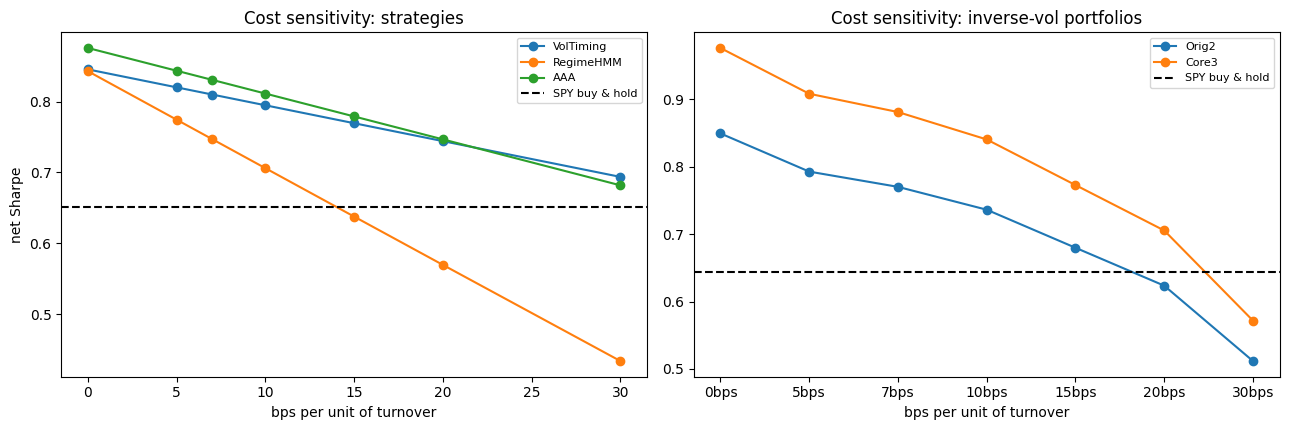

In [17]:
levels = list(ROBUSTNESS_CONFIG.cost_grid_bps)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.4))
for name in cost_strategies.index:
    ax1.plot(levels, cost_strategies.loc[name].values, marker="o", label=name)
ax1.axhline(sharpe(spy.loc[oos_start:]), color="black", ls="--", label="SPY buy & hold")
ax1.set_xlabel("bps per unit of turnover"); ax1.set_ylabel("net Sharpe")
ax1.set_title("Cost sensitivity: strategies"); ax1.legend(fontsize=8)
cost_ports.plot(ax=ax2, marker="o", title="Cost sensitivity: inverse-vol portfolios")
ax2.axhline(sharpe(spy.loc[port_start:]), color="black", ls="--", label="SPY buy & hold")
ax2.set_xlabel("bps per unit of turnover"); ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 6c. Parameter sensitivity

AAA is re-run over a grid of nearby parameters, scored on the same out-of-sample window. We are
looking for a *plateau* of good cells, not a single lucky peak. The originals each have one free
parameter, varied the same way.

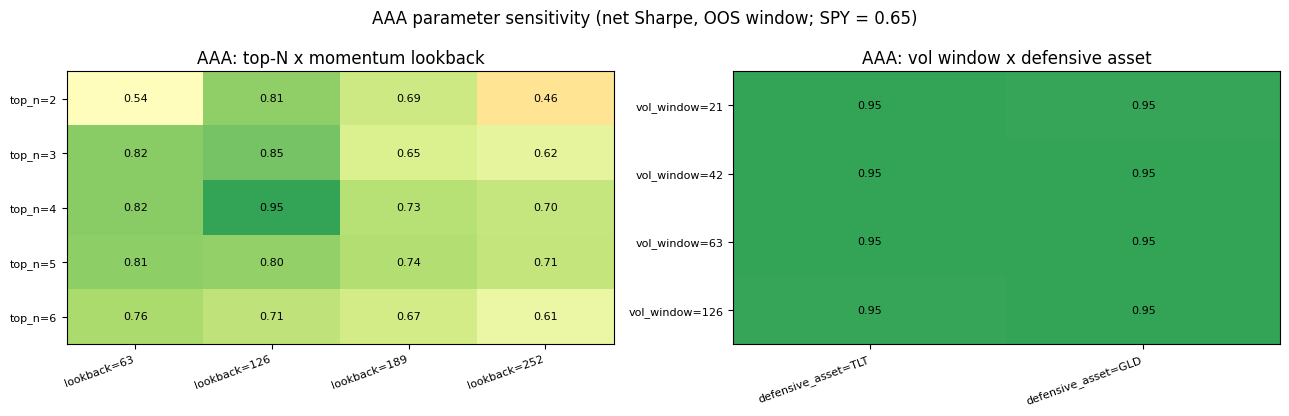

,lookback=63,lookback=126,lookback=189,lookback=252
top_n=2,0.54,0.81,0.69,0.46
top_n=3,0.82,0.85,0.65,0.62
top_n=4,0.82,0.95,0.73,0.70
top_n=5,0.81,0.80,0.74,0.71
top_n=6,0.76,0.71,0.67,0.61


,defensive_asset=TLT,defensive_asset=GLD
vol_window=21,0.95,0.95
vol_window=42,0.95,0.95
vol_window=63,0.95,0.95
vol_window=126,0.95,0.95


In [18]:
grid_aaa = parameter_grid(prices, returns, adaptive_allocation.build_positions, AAA_CONFIG,
                          {"top_n": [2, 3, 4, 5, 6], "lookback": [63, 126, 189, 252]},
                          TC, SLIP, start=oos_start)
grid_aaa_vol = parameter_grid(prices, returns, adaptive_allocation.build_positions, AAA_CONFIG,
                              {"vol_window": [21, 42, 63, 126], "defensive_asset": ["TLT", "GLD"]},
                              TC, SLIP, start=oos_start)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, (g, title) in zip(axes, ((grid_aaa, "top-N x momentum lookback"),
                                 (grid_aaa_vol, "vol window x defensive asset"))):
    im = ax.imshow(g.values.astype(float), cmap="RdYlGn", vmin=0, vmax=1.1, aspect="auto")
    ax.set_xticks(range(g.shape[1])); ax.set_xticklabels(g.columns, rotation=20, ha="right", fontsize=8)
    ax.set_yticks(range(g.shape[0])); ax.set_yticklabels(g.index, fontsize=8)
    for i in range(g.shape[0]):
        for j in range(g.shape[1]):
            ax.text(j, i, f"{float(g.values[i, j]):.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(f"AAA: {title}")
fig.suptitle(f"AAA parameter sensitivity (net Sharpe, OOS window; SPY = {sharpe(spy.loc[oos_start:]):.2f})")
plt.tight_layout()
plt.show()
display(grid_aaa.round(2))
grid_aaa_vol.round(2)

### 6d. Overlay sensitivity

Does the headline portfolio depend on the turnover cap or the volatility target?

In [19]:
rows = {}
for cap in ROBUSTNESS_CONFIG.turnover_caps:
    for target in ROBUSTNESS_CONFIG.vol_targets:
        m = performance_metrics(build_portfolio(core3, "inverse_volatility",
                                                turnover_cap=cap, target_volatility=target)["returns"])
        rows[(f"cap {cap:.2f}", f"vol {target:.0%}")] = {
            "sharpe": m["sharpe_ratio"], "max_drawdown": m["max_drawdown"], "cagr": m["cagr"]}
pd.DataFrame(rows).T.round(3)

sharpe  max_drawdown   cagr
cap 0.10 vol 8%    0.891        -0.136  0.075
         vol 10%   0.881        -0.168  0.091
         vol 12%   0.872        -0.199  0.105
cap 0.20 vol 8%    0.891        -0.136  0.075
         vol 10%   0.881        -0.168  0.091
         vol 12%   0.871        -0.199  0.105
cap 0.35 vol 8%    0.891        -0.136  0.075
         vol 10%   0.881        -0.168  0.091
         vol 12%   0.871        -0.199  0.105
cap 0.50 vol 8%    0.891        -0.136  0.075
         vol 10%   0.881        -0.168  0.091
         vol 12%   0.871        -0.199  0.105
cap 1.00 vol 8%    0.891        -0.136  0.075
         vol 10%   0.881        -0.168  0.091
         vol 12%   0.871        -0.199  0.105

## Step 7 - Risk analysis

Four views of risk that a metrics table cannot give: what actually happened in named crises, what
could plausibly happen next year, how long the drawdowns lasted, and which market states each
strategy earns its return in.

### 7a. Historical stress episodes

Rather than inventing shocks, we replay each strategy through the worst episodes in the sample.
Because the sample starts in 2004, the out-of-sample window includes the 2008 crisis.

In [20]:
stress_named = {**named, "Core3 inv-vol": headline, "SPY": spy, "60/40": sixty_forty}
stress = stress_test(stress_named)
display(stress.round(3))
stress_test(stress_named, statistic="max_drawdown").round(3)

,VolTiming,RegimeHMM,AAA,Core3 inv-vol,SPY,60/40
2008 global financial crisis,-0.288,-0.088,0.242,-0.099,-0.540,-0.286
2010 flash crash / euro scare,-0.115,-0.066,-0.074,-0.079,-0.147,-0.034
2011 US downgrade / euro crisis,-0.132,-0.030,0.219,0.013,-0.163,0.018
2015 China deval / Aug flash crash,-0.092,-0.056,-0.007,-0.049,-0.085,-0.045
2018 Feb VIX spike,-0.067,-0.050,-0.053,-0.068,-0.041,-0.040
2018 Q4 rate-hike selloff,-0.125,-0.065,-0.013,-0.087,-0.135,-0.065
2020 COVID crash,-0.105,-0.053,-0.061,-0.088,-0.172,-0.031
2022 inflation / hiking cycle,-0.118,-0.107,-0.063,-0.123,-0.177,-0.240
2025 tariff shock,-0.040,-0.047,-0.033,-0.048,-0.005,-0.023


,VolTiming,RegimeHMM,AAA,Core3 inv-vol,SPY,60/40
2008 global financial crisis,-0.301,-0.116,-0.079,-0.129,-0.552,-0.299
2010 flash crash / euro scare,-0.125,-0.073,-0.113,-0.087,-0.157,-0.050
2011 US downgrade / euro crisis,-0.153,-0.044,-0.053,-0.031,-0.184,-0.065
2015 China deval / Aug flash crash,-0.110,-0.063,-0.043,-0.060,-0.111,-0.068
2018 Feb VIX spike,-0.107,-0.061,-0.100,-0.099,-0.101,-0.076
2018 Q4 rate-hike selloff,-0.157,-0.068,-0.058,-0.104,-0.192,-0.102
2020 COVID crash,-0.136,-0.054,-0.169,-0.114,-0.337,-0.178
2022 inflation / hiking cycle,-0.156,-0.118,-0.127,-0.137,-0.245,-0.264
2025 tariff shock,-0.089,-0.047,-0.054,-0.059,-0.147,-0.105


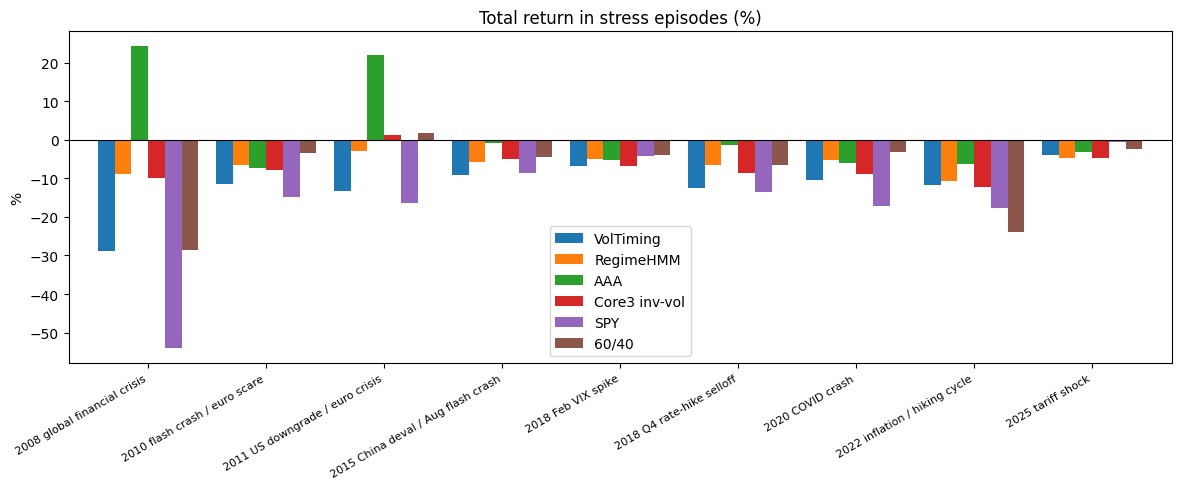

In [21]:
show = stress[["VolTiming", "RegimeHMM", "AAA", "Core3 inv-vol", "SPY", "60/40"]]
(show * 100).plot.bar(figsize=(12, 5), width=0.85, title="Total return in stress episodes (%)")
plt.axhline(0, color="black", lw=0.8)
plt.xticks(rotation=30, ha="right", fontsize=8)
plt.ylabel("%")
plt.tight_layout()
plt.show()

### 7b. Monte Carlo (stationary block bootstrap)

Resampling single days would destroy volatility clustering, so we resample *blocks* of consecutive
days with random lengths averaging 21. Each of the 5000 paths is a plausible alternative year built
from the strategy's own return distribution.

In [22]:
mc = monte_carlo_table({**key, "AAA": strategies["adaptive_allocation"]})
mc.round(3)

,horizon_days,n_paths,median_return,mean_return,p5_return,p95_return,prob_loss,mc_var_95,mc_es_95,median_max_drawdown,p95_max_drawdown
Orig2 inv-vol,252.0,5000.0,0.077,0.083,-0.084,0.266,0.222,0.084,0.120,-0.079,-0.154
Orig2 equal,252.0,5000.0,0.081,0.084,-0.082,0.261,0.218,0.082,0.119,-0.081,-0.152
Core3 inv-vol,252.0,5000.0,0.091,0.096,-0.073,0.280,0.189,0.073,0.112,-0.078,-0.153
Core3 equal,252.0,5000.0,0.101,0.104,-0.071,0.286,0.170,0.071,0.107,-0.077,-0.151
Core3 Markowitz reg.,252.0,5000.0,0.087,0.090,-0.083,0.272,0.214,0.083,0.123,-0.078,-0.158
SPY,252.0,5000.0,0.129,0.126,-0.177,0.420,0.234,0.177,0.254,-0.132,-0.337
60/40,252.0,5000.0,0.096,0.094,-0.091,0.270,0.186,0.091,0.138,-0.081,-0.203
AAA,252.0,5000.0,0.085,0.090,-0.069,0.263,0.180,0.069,0.107,-0.073,-0.161


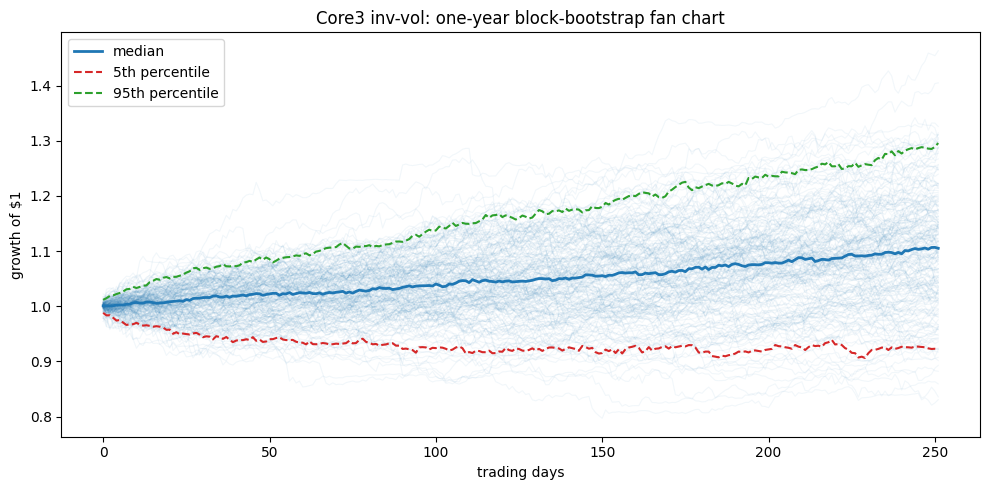

In [23]:
paths = monte_carlo_paths_frame(headline.dropna(), n_paths=200)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(paths, color="tab:blue", alpha=0.06, lw=0.8)
ax.plot(paths.median(axis=1), color="tab:blue", lw=2, label="median")
ax.plot(paths.quantile(0.05, axis=1), color="tab:red", ls="--", label="5th percentile")
ax.plot(paths.quantile(0.95, axis=1), color="tab:green", ls="--", label="95th percentile")
ax.set_title("Core3 inv-vol: one-year block-bootstrap fan chart")
ax.set_xlabel("trading days"); ax.set_ylabel("growth of $1"); ax.legend()
plt.tight_layout()
plt.show()

### 7c. Drawdown episodes

A maximum drawdown number hides how long the pain lasted. This lists the deepest episodes with the
dates and the time to trough and to recovery.

In [24]:
display(drawdown_table(headline.dropna(), top_n=5))
drawdown_table(spy.loc[port_start:], top_n=5)

,peak,trough,recovery,depth,days_to_trough,days_to_recover
0,2021-11-08,2022-11-09,2024-01-24,-0.167939,253,301.0
1,2008-05-19,2009-07-08,2010-01-04,-0.144863,286,124.0
2,2015-04-24,2016-01-11,2017-02-13,-0.142085,180,275.0
3,2020-01-17,2020-03-18,2021-01-07,-0.134977,41,204.0
4,2018-01-26,2018-12-24,2019-04-04,-0.112322,229,69.0


,peak,trough,recovery,depth,days_to_trough,days_to_recover
0,2007-10-09,2009-03-09,2012-08-16,-0.551894,355,869.0
1,2020-02-19,2020-03-23,2020-08-10,-0.337173,23,97.0
2,2022-01-03,2022-10-12,2023-12-13,-0.244964,195,294.0
3,2018-09-20,2018-12-24,2019-04-12,-0.193489,65,75.0
4,2025-02-19,2025-04-08,2025-06-26,-0.187552,34,54.0


### 7d. Regime-conditioned performance

Which market states does each strategy earn its return in? The HMM labels here describe the whole
sample, so they are a *description* of when returns arrived, not a tradable signal.

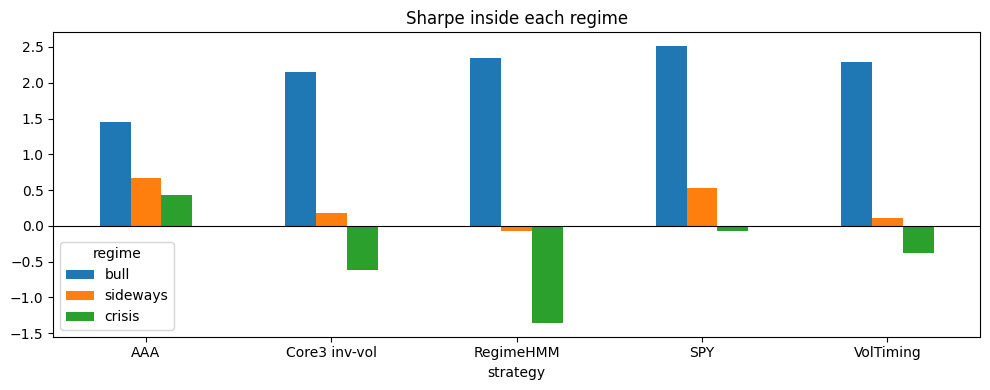

regime,bull,sideways,crisis
strategy,,,
AAA,1.45,0.67,0.43
Core3 inv-vol,2.16,0.18,-0.62
RegimeHMM,2.35,-0.07,-1.36
SPY,2.51,0.53,-0.07
VolTiming,2.30,0.11,-0.38


In [25]:
regime_features = build_regime_features(log_returns[benchmark_asset],
                                       realized_vol[benchmark_asset].reindex(log_returns.index))
regime_labels = map_regimes_to_labels(
    infer_regimes(fit_hmm_regime_model(regime_features), regime_features),
    log_returns[benchmark_asset])["regime_label"]

rc = regime_conditioned_table({**named, "Core3 inv-vol": headline, "SPY": spy.loc[oos_start:]}, regime_labels)
regime_sharpe = rc["sharpe"].unstack("regime")[["bull", "sideways", "crisis"]]
regime_sharpe.plot.bar(figsize=(10, 4), title="Sharpe inside each regime")
plt.axhline(0, color="black", lw=0.8)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
regime_sharpe.round(2)

In [26]:
calendar = calendar_year_returns(key)
(calendar * 100).round(1)

,Orig2 inv-vol,Orig2 equal,Core3 inv-vol,Core3 equal,Core3 Markowitz reg.,SPY,60/40
2006,3.6,11.4,3.9,14.7,0.0,6.6,4.1
2007,0.9,-0.6,5.9,3.8,6.1,5.1,7.8
2008,-8.7,-11.7,-1.6,1.0,13.1,-36.8,-11.8
2009,4.1,8.2,3.8,6.4,6.3,26.4,6.0
2010,12.3,12.3,11.7,12.1,13.4,15.1,13.8
2011,5.5,2.7,13.4,12.3,14.2,1.9,15.9
2012,15.9,15.0,14.9,16.9,5.9,16.0,11.1
2013,20.4,20.6,13.4,15.9,19.8,32.3,12.2
2014,4.8,4.9,12.5,9.2,9.1,13.5,19.3
2015,-4.4,-3.9,-5.4,-5.6,-7.2,1.2,0.8


### Reading the results

* **AAA earns its place.** Adding it to the original two-strategy book raises the portfolio Sharpe
  and cuts the drawdown, and it is the only strategy that was positive through 2008 and 2011.
* **Correlation is why.** Volatility timing and regime switching correlate about 0.84 with each other;
  AAA correlates about 0.4 with both. Two versions of the same bet do not diversify.
* **Simple weighting wins.** Equal weight and inverse volatility beat both Markowitz variants,
  because expected-return estimates are noise at this sample size.
* **The result is not fragile.** It survives every sub-period, tripled costs, the parameter grid and
  both overlay knobs.
* **The known weakness is 2022**, when stocks and bonds fell together and the defensive asset gave no
  shelter. That episode is the worst drawdown in the book.